**V1.1.1** Simplest CNN with :

`input` = 9000 Samples

`Output classes` = 4

In [1]:
!powershell.exe  -c "get-location"


Path                                 
----                                 
C:\Project\Research-Project\Notebooks




In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split # for test train split
import matplotlib.pyplot as plt

import plotly.express as px # to analyse the ECG plot on the HTML window  

import tensorflow as tf

In [3]:
input_dataset_DF_file = r"C:\Project\Research-Project\DataFrame_Extracts\processed_annotations.csv"

input_dataset_DF = pd.read_csv(input_dataset_DF_file)
input_dataset_DF.head()

,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units
0,A00001,N,C:\Project\Research-Project\training2017\\A00001,300,9000,1,mV
1,A00002,N,C:\Project\Research-Project\training2017\\A00002,300,9000,1,mV
2,A00003,N,C:\Project\Research-Project\training2017\\A00003,300,18000,1,mV
3,A00004,A,C:\Project\Research-Project\training2017\\A00004,300,9000,1,mV
4,A00005,A,C:\Project\Research-Project\training2017\\A00005,300,18000,1,mV


In [4]:
input_dataset_DF.columns

Index(['SampleID', 'Inference', 'Matlab_files', 'Sampling_Rate_Hz',
       'Signal_Length_Samples', 'Num_Channels', 'Units'],
      dtype='object')

In [5]:
Sample_wtih_9k_points = input_dataset_DF[input_dataset_DF["Signal_Length_Samples"] == 9000]
Sample_wtih_9k_points.shape

(5977, 7)

In [6]:
Sample_wtih_9k_points.head()

,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units
0,A00001,N,C:\Project\Research-Project\training2017\\A00001,300,9000,1,mV
1,A00002,N,C:\Project\Research-Project\training2017\\A00002,300,9000,1,mV
3,A00004,A,C:\Project\Research-Project\training2017\\A00004,300,9000,1,mV
5,A00006,N,C:\Project\Research-Project\training2017\\A00006,300,9000,1,mV
6,A00007,N,C:\Project\Research-Project\training2017\\A00007,300,9000,1,mV


Lets make the dataframe visually appealing

In [7]:
# Define your custom palette strings
vc_pink = "background-color: #FF3399; color: white; font-weight: bold;"
vc_green = "background-color: #00F5D4; color: #00221C; font-weight: bold;" # Radar Neon Green
vc_shadow = "background-color: #3C0A23; color: #FF3399;"                     # Dark HUD Theme

# Apply styles to specific column targets
# Note : we're doing a Sample_wtih_9k_points.head(10) because styler is like 6-Star wanted level in GTA: Vice city, once you call
# style, it will solely focus on rendering the colors on the complete dataframe, it won't stop at 5 or 10 samples.
# You'll see a full Dataframe 0f 6000ish records in color in the single column.
styled_df = Sample_wtih_9k_points.head(10).style\
    .applymap(lambda x: vc_pink, subset=["Sampling_Rate_Hz", "Signal_Length_Samples"])\
    .applymap(lambda x: vc_green, subset=["Inference"])\
    .applymap(lambda x: vc_shadow, subset=["SampleID", "Matlab_files"])

# Render the styled dataframe in your notebook
# styled_df 

C:\Users\Varun\AppData\Local\Temp\ipykernel_19296\813645930.py:10: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_df = Sample_wtih_9k_points.head(10).style\


In [8]:
styled_df

,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units
0,A00001,N,C:\Project\Research-Project\training2017\\A00001,300,9000,1,mV
1,A00002,N,C:\Project\Research-Project\training2017\\A00002,300,9000,1,mV
3,A00004,A,C:\Project\Research-Project\training2017\\A00004,300,9000,1,mV
5,A00006,N,C:\Project\Research-Project\training2017\\A00006,300,9000,1,mV
6,A00007,N,C:\Project\Research-Project\training2017\\A00007,300,9000,1,mV
8,A00009,A,C:\Project\Research-Project\training2017\\A00009,300,9000,1,mV
10,A00011,N,C:\Project\Research-Project\training2017\\A00011,300,9000,1,mV
11,A00012,N,C:\Project\Research-Project\training2017\\A00012,300,9000,1,mV
12,A00013,O,C:\Project\Research-Project\training2017\\A00013,300,9000,1,mV
15,A00016,N,C:\Project\Research-Project\training2017\\A00016,300,9000,1,mV


In [9]:
X = Sample_wtih_9k_points.drop(columns=["Inference"])
Y = Sample_wtih_9k_points["Inference"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print(f" X_train shape: {X_train.shape} , X_test shape:{X_test.shape}, \n  y_train shape:{y_train.shape}, y_test shape:{y_test.shape}")

 X_train shape: (4781, 6) , X_test shape:(1196, 6), 
  y_train shape:(4781,), y_test shape:(1196,)


    function that Reads a pre-filtered ECG record that is known to be exactly 9000 samples.
    Returns a pristine (9000, 1) float32 numpy array ready for Conv1D.
    

In [11]:
import numpy as np
import wfdb

def get_exact_1d_ecg_input(matlab_filepath):

    # Clean file extensions if present
    record_path = str(matlab_filepath).replace('.mat', '').replace('.hea', '')
    
    try:
        # 1. Read raw voltage signals
        record = wfdb.rdrecord(record_path)
        signal = record.p_signal 
        
        # Pull the primary single lead channel (Lead I)
        lead_data = signal[:, 0]
        
        # 2. Safety Check (Ensures it matches your filtered 9000 constraint)
        if len(lead_data) != 9000:
            raise ValueError(f"Record length is {len(lead_data)}, expected exactly 9000.")
            
        # 3. Add the required Keras channel dimension and cast to float32
        # Transforms shape from (9000,) to (9000, 1)
        cnn_input_1d = np.expand_dims(lead_data, axis=-1).astype('float32')
        
        return cnn_input_1d

    except Exception as e:
        print(f"🚨 Skipping record {record_path} due to error: {e}")
        return None

<Axes: >

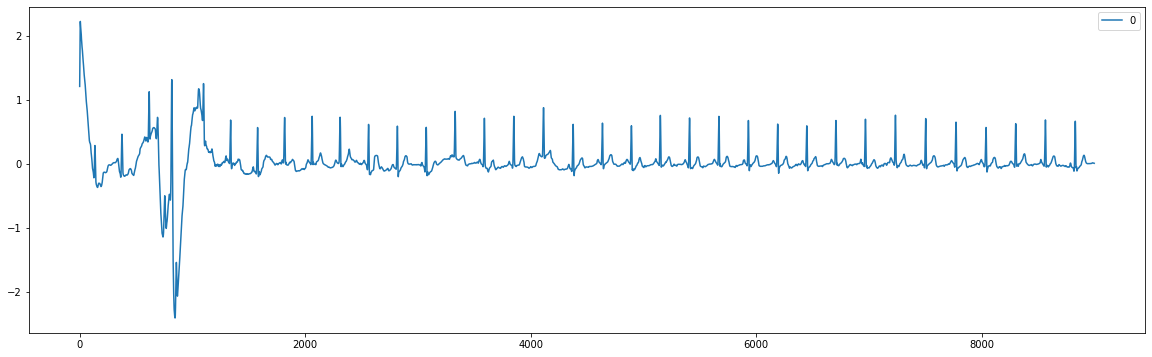

In [12]:
test_sample = pd.DataFrame(get_exact_1d_ecg_input(
    X_train.iloc[1].Matlab_files             
    ))
test_sample.plot(figsize=(20,6)) 

Lets add the gridlines similar to what we have on the paper ECG to see
1. how long each beat is
2. how long the P-wave, QRS-complex, T-wave is 
3. how long it takes for the transition to take place from :
    1. p-wave -> QRS-complex; 
    2. QRS-complex->T-wave ; 
    3. QRS-complex
    4. Q to R point
    5. R to T point 

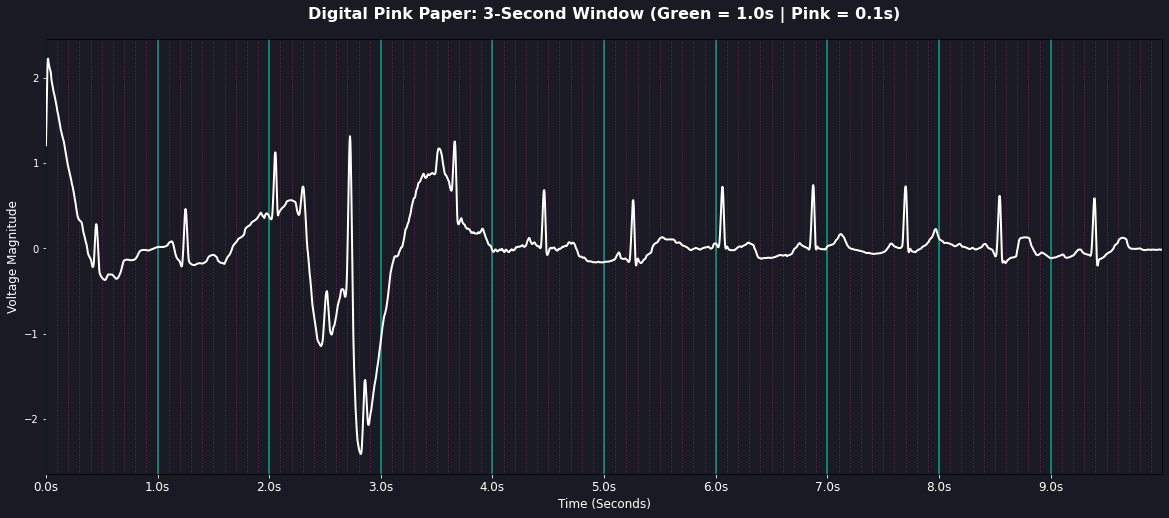

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Take a 3-second slice (3 seconds * 300 Hz = 900 samples)
window_size = 3000
sample_slice = test_sample.iloc[0:window_size]

# 2. Initialize the plot workspace
fig, ax = plt.subplots(figsize=(20, 8))

# 3. Plot the raw signal line
ax.plot(sample_slice.index, sample_slice.iloc[:, 0], color='white', linewidth=2, label="ECG Lead I", zorder=3)

# 4. Generate the positions for your gridlines based on your 300 Hz frequency
x_indices = sample_slice.index

# Minor Grid: 0.1 seconds apart (Every 30 samples)
minor_ticks = np.arange(x_indices[0], x_indices[-1] + 1, 30)
# Major Grid: 1.0 second apart (Every 300 samples)
major_ticks = np.arange(x_indices[0], x_indices[-1] + 1, 300)

# 5. Draw the custom "Analog Graph Paper" Gridlines
# Minor lines (0.1s) - Soft neon pink dash
for t in minor_ticks:
    ax.axvline(x=t, color='#FF3399', linestyle=':', alpha=0.35, linewidth=1, zorder=1)

# Major lines (1.0s) - Bold neon green solid
for t in major_ticks:
    ax.axvline(x=t, color='#00F5D4', linestyle='-', alpha=0.6, linewidth=1.5, zorder=2)

# 6. Formatting the HUD display
ax.set_facecolor('#1a1a24') # Dark background to make the neon pop
fig.patch.set_facecolor('#1a1a24')

ax.set_xticks(major_ticks)
ax.set_xticklabels([f"{t/300:.1f}s" for t in major_ticks], color='white', fontsize=12)
ax.tick_params(colors='white')

ax.set_title("Digital Pink Paper: 3-Second Window (Green = 1.0s | Pink = 0.1s)", color='white', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel("Time (Seconds)", color='white', fontsize=12)
ax.set_ylabel("Voltage Magnitude", color='white', fontsize=12)

plt.xlim(x_indices[0], x_indices[-1])
plt.show()

Adding the same gridlines to the   **plotly.express** 
we will analyse the waveform in the compiled HTML 

In [14]:
import plotly.express as px

# 1. Use your sample dataset
plot_data = test_sample

# 2. Create the base interactive line chart
fig = px.line(
    plot_data, 
    title='<b>ECG Waveform Analysis (Interactive Analog Grid)</b>',
)

# 3. Apply custom line styles and markers
fig.update_traces(mode="lines+markers", line=dict(color="white", width=2)) 

# 4. Configure the Dark HUD Background and Gridlines
fig.update_layout(
    plot_bgcolor='#1a1a24',  
    paper_bgcolor='#1a1a24', 
    font=dict(color='white'),
    title_font=dict(size=16),
    showlegend=False,
    
    # === FORCE MOUSE CLICK TO MOVE LEFT/RIGHT ===
    dragmode='pan' 
)
# 5. Build the Major Green Grid (1.0s) on the X-Axis
fig.update_xaxes(
    showspikes=True, 
    spikecolor="gray", 
    spikesnap="cursor", 
    spikemode="across",
    showgrid=True,
    gridwidth=1.5,
    gridcolor='#00F5D4',       # Major Grid: Neon Green (1.0s)
    dtick=300,                 # Every 300 samples (1.0 second)
    tickcolor='white'
)

# 6. Clean up the Y-Axis to match the dark theme
fig.update_yaxes(
    showspikes=True, 
    spikecolor="gray", 
    spikemode="across",
    gridcolor='rgba(255, 255, 255, 0.1)', 
    tickcolor='white'
)

# 7. VERSION FIX: Manually inject Pink Minor Gridlines (0.1s / Every 30 samples)
# This loops through your data and creates vertical background lines
minor_lines = []
for x_val in range(0, len(plot_data), 30):
    # Skip points where the major green line already draws (every 300 samples)
    if x_val % 300 == 0:
        continue
        
    minor_lines.append(
        dict(
            type="line",
            xref="x", yref="paper", # Span top to bottom of the chart area
            x0=x_val, x1=x_val,
            y0=0, y1=1,
            line=dict(color="rgba(255, 51, 153, 0.3)", width=1, dash="dot"),
            layer="below" # Make sure lines sit beautifully BEHIND your data line
        )
    )

# Assign the custom shapes to the layout
fig.update_layout(shapes=minor_lines)

# Save or render out to your HTML extract
fig.show(renderer="notebook_connected")

The plan was clear:
1. A stationary gridline representation of $0.1\text{s}$ and $1\text{s}$ time intervals acting as the absolute background.
2. A moveable ECG plot operating in the foreground.
3. The ability to manually slide the ECG back and forth over that fixed grid to instantly eyeball and verify the lengths of each individual cardiac segment.

However, the rendering engine collapsed under its own internal rules. Plotly cannot maintain two independent coordinate systems—one static and one dynamic—on the same canvas. The moment you pan, the grid slides with the data.

It was exactly like Saito lying on the floor of his "secret apartment," realizing the architecture was a fake:

**`I've always hated this carpet. It's stained and frayed in such distinctive ways. But very definitely made of wool. Right now… I'm lying on polyester. Which means, I'm not lying on my carpet in my apartment. You have lived up to your reputation, Mr. Cobb. I'm still dreaming.`
**

Except in our configuration:
1. We are portraying Saito, auditing the integrity of the construct.
2. The interactive Plotly canvas is Saito's apartment.
3. The anchored gridlines moving locked with the ECG is the polyester carpet—the definitive giveaway that the viewport isn't behaving like physical graph paper.

In [15]:
import plotly.express as px

# 1. Use your sample dataset
plot_data = test_sample

# 2. Create the base interactive line chart
fig = px.line(
    plot_data, 
    title='<b>ECG Sliding Test (Stationary Grid Paper)</b>',
)

fig.update_traces(mode="lines+markers", line=dict(color="white", width=2)) 

# 3. Strip out the native moving grid completely
fig.update_xaxes(showgrid=False, zeroline=False, showspikes=True, tickcolor='white')
fig.update_yaxes(showgrid=False, zeroline=False, showspikes=True, tickcolor='white')

# 4. Inject a stationary SVG grid pattern image behind the plot
# This image remains 100% frozen on screen while you pan the data!
fig.update_layout(
    plot_bgcolor='#1a1a24',  
    paper_bgcolor='#1a1a24', 
    font=dict(color='white'),
    dragmode='pan',
    showlegend=False,
    
    images=[dict(
        # A tiny pre-calculated SVG string that tiles a green and pink grid
        source="data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' width='300' height='100'><rect width='300' height='100' fill='%231a1a24'/><path d='M30,0 v100 M60,0 v100 M90,0 v100 M120,0 v100 M150,0 v100 M180,0 v100 M210,0 v100 M240,0 v100 M270,0 v100' stroke='%23FF3399' stroke-width='1' stroke-opacity='0.25' stroke-dasharray='2,2'/><path d='M300,0 v100' stroke='%2300F5D4' stroke-width='1.5' stroke-opacity='0.6'/></svg>",
        xref="paper", yref="paper", # Lock it strictly to the display window frame
        x=0, y=1,
        sizex=1, sizey=1,
        xanchor="left", yanchor="top",
        sizing="stretch", # Fill the whole viewport
        layer="below"     # Keep it behind the white ECG line
    )]
)

fig.show(renderer="notebook_connected")

We will now build the base model

    # Input shape: 9000 time-series points, 1 single signal lead
    first convolution later
    **filters=32**,     # industry standard - but we can furyher downsize it to 16 and see if the model's prediction ability is still the same
                    # the idea behind was 32 filteres for 2D image so 16 filters for 1D image should be enough 

    **kernel_size=6**,  # Typical ECG has 0.8 seconds for a beat.
                        # 9000 samples represent 30 seconds of ECG; so 1 second → 300 samples; 1 ms = 300/1000 = 0.3 data points. 
                        # 1 full cycle is typically 0.8 seconds
                        # so 30 seconds will have 37.5 ish beats
                        # so 1 beat in the samples will have 9000/37.5 = 240 data-points
                        # The fastest transitions are for the QRS interval - typically 70-110 ms  (Q wave → R wave); (R wave → T wave)  
                        # so 70 ms = 70x(samples for 1 ms) = 70x0.3 = 21 samples. similarly 110 ms =110x0.3 = 33 samples
                        # BUT 
                        # A normal, sharp Q → R upstroke typically takes only 20-30 ms
                        # so, 20x0.3 = 6 samples, 30x0.3 = 9 samples.
                    # choosing the lower value so that the model can see the traisition,we choose conv. kernel filter size as 6                    

    **activation='relu'** # after the convolver takes 6 samples, multiplies and sums them up, the ReLU just checks if the value is positive or negative. this helps in speeding up the process as opposed to tanh(x) or sigmoid(x) which is heavy on the math.

    **input_shape**=(9000, 1) -  we had pre-choosen the samples with size=9000 points
                  
                  
    layers.MaxPooling1D(pool_size=2) - so that the learned features stay sharp and propogate down the line. if this was avg pooling, then, the work done by previous layers woud have been undone straightaway

    

In [16]:
from tensorflow.keras import layers, models

model_1d = models.Sequential([
    # Block 1: Catching raw features
    layers.Conv1D(filters=32, kernel_size=7, activation='relu', input_shape=(9000, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=4), # Downsample aggressive early on
    
    # Block 2: Middle-level patterns
    layers.Conv1D(filters=64, kernel_size=5, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=4),
    
    # Block 3: Deep contextual patterns
    layers.Conv1D(filters=128, kernel_size=3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=4), # Your sequence is now compressed perfectly
    
    # The Global Bottleneck
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.5),

    # Classifier Head
    layers.Dense(64, activation='relu'),
    layers.Dense(4, activation='softmax')
])

model_1d.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 8994, 32)          256       
                                                                 
 batch_normalization (BatchN  (None, 8994, 32)         128       
 ormalization)                                                   
                                                                 
 max_pooling1d (MaxPooling1D  (None, 2248, 32)         0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 2244, 64)          10304     
                                                                 
 batch_normalization_1 (Batc  (None, 2244, 64)         256       
 hNormalization)                                                 
                                                        

In [17]:
model_1d.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 8994, 32)          256       
                                                                 
 batch_normalization (BatchN  (None, 8994, 32)         128       
 ormalization)                                                   
                                                                 
 max_pooling1d (MaxPooling1D  (None, 2248, 32)         0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 2244, 64)          10304     
                                                                 
 batch_normalization_1 (Batc  (None, 2244, 64)         256       
 hNormalization)                                                 
                                                        

In [18]:
Sample_wtih_9k_points.Sampling_Rate_Hz.value_counts

<bound method IndexOpsMixin.value_counts of 0       300
1       300
3       300
5       300
6       300
       ... 
8522    300
8523    300
8524    300
8526    300
8527    300
Name: Sampling_Rate_Hz, Length: 5977, dtype: int64>

This function DOES NOT return a traditional DataFrame or a massive NumPy array containing the loaded training data. 


1. Instead, it returns a lazy-evaluated TensorFlow Dataset Stream. 
2. The Matlab files are NOT read from disk when this function is called.
3. How it executes:
    1. It acts as an on-demand conveyor belt. It holds the file locations  
    2. only reads the actual Matlab files, extracts the 9000-point arrays,  
    3. and yields them in chunks of 32 dynamically when the training loop requests the next batch.(described in the next function)

In [19]:
# ==============================================================================
# 1. THE EXTERNAL GENERATOR (Moved Outside)
# ==============================================================================
def external_data_generator(df, path_col, label_col):
    """ Pure loop logic that lives independently outside the main pipeline setup. """
    for _, row in df.iterrows():
        file_path = row[path_col]
        label = row[label_col]
        
        # Pull your 9000-point array using your existing file reader
        ecg_array = get_exact_1d_ecg_input(file_path)
        
        # Yield one single sample over the fence
        yield ecg_array, label


# ==============================================================================

In [20]:
# 1. Define the core generator function
def data_generator(df, path_col, label_col):
    # Optional: Shuffle the rows at the start of an epoch to randomize training
    current_df = df.sample(frac=1).reset_index(drop=True)
    
    for _, row in current_df.iterrows():
        file_path = row[path_col]
        label = row[label_col]
        
        # --- USE YOUR EXISTING FUNCTION HERE ---
        # This calls the function you already have that returns the (9000, 1) numpy array
        ecg_array = get_exact_1d_ecg_input(file_path) 
        
        # Yield the single isolated array and its corresponding label
        yield ecg_array, label

# 1. Define the core generator function
def data_generator(df, path_col, label_col):
    # Create a quick mapping dictionary for your cardiac classes
    # (Add any other string classes you have in your dataset here!)
    label_mapping = {
        'N': 0,
        'A': 1,
        'O': 2,
        '~': 3
    }
    
    # Optional: Shuffle the rows at the start of an epoch
    current_df = df.sample(frac=1).reset_index(drop=True)
    
    for _, row in current_df.iterrows():
        file_path = row[path_col]
        raw_label = row[label_col]  # This is grabbing "N"
        
        # --- THE FIX: Convert the string label to its matching integer ---
        # If the label isn't in our map, default it to 0 or throw an error
        label = label_mapping.get(raw_label, 0) 
        
        # Pull your 9000-point array using your existing file reader
        ecg_array = get_exact_1d_ecg_input(file_path) 
        
        # Yield the clean numpy array and the integer label
        yield ecg_array, label        

In [21]:
data_generator(Sample_wtih_9k_points, "Matlab_files", "Inference")

<generator object data_generator at 0x0000012E3EBCAAB0>

In [22]:
import tensorflow as tf
import numpy as np



# 2. THE PIPELINE CREATOR
# ==============================================================================
def create_ecg_dataset(df, path_col, label_col, batch_size=32, shuffle=True):
    
    # Handle your optional shuffling right at the start
    current_df = df.sample(frac=1).reset_index(drop=True) if shuffle else df

    # tf.data.Dataset.from_generator will be act like an orchestrator
    # it will take function name, its parameters from us but it will decide on its own on when to actually call the function
    dataset = tf.data.Dataset.from_generator(
        generator=lambda: data_generator(current_df, path_col, label_col),
        output_signature=(
            tf.TensorSpec(shape=(9000, 1), dtype=tf.float32), # Expected input shape
            tf.TensorSpec(shape=(), dtype=tf.int32)           # Scalar label
        ),

    )
    
    # Batch and prefetch
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    
    return dataset

In [23]:
model_1d.compile( optimizer='adam', 
               loss='sparse_categorical_crossentropy', 
               metrics=['accuracy'])


In [24]:
from sklearn.model_selection import train_test_split

# 1. Split your path DataFrame (80% train paths, 20% test paths)
train_df, test_df = train_test_split(Sample_wtih_9k_points, test_size=0.20, random_state=42)

# 2. Build the streaming pipelines using the function above
train_dataset = create_ecg_dataset(train_df, path_col='Matlab_files', label_col='Inference', batch_size=32, shuffle=True)
test_dataset = create_ecg_dataset(test_df, path_col='Matlab_files', label_col='Inference', batch_size=32, shuffle=False)



In [25]:
train_df.head()

,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units
2335,A02336,N,C:\Project\Research-Project\training2017\\A02336,300,9000,1,mV
4419,A04420,N,C:\Project\Research-Project\training2017\\A04420,300,9000,1,mV
7089,A07090,N,C:\Project\Research-Project\training2017\\A07090,300,9000,1,mV
3277,A03278,O,C:\Project\Research-Project\training2017\\A03278,300,9000,1,mV
1607,A01608,O,C:\Project\Research-Project\training2017\\A01608,300,9000,1,mV


In [26]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Set up the auto-save configuration so taht in the event of a readbump, we don't loose 2+ hours of trainning

checkpoint_File = 'C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.2.h5' 
checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_File,             # The file path where it saves to disk
    monitor='val_loss',                   # Look at validation loss to judge performance
    save_best_only=True,                  # ONLY overwrite the file if the model improved!
    mode='min',                           # We want the lowest possible validation loss
    verbose=1                             # Print a message whenever it auto-saves
)

from tensorflow.keras.callbacks import ModelCheckpoint

# Set up the auto-save configuration so taht in the event of a readbump, we don't loose 2+ hours of trainning
checkpoint_callback = ModelCheckpoint(
    filepath='C:\Project\Research-Project\Models\ecg_model_checkpoint.h5',  # The file path where it saves to disk
    monitor='val_loss',                   # Look at validation loss to judge performance
    save_best_only=True,                  # ONLY overwrite the file if the model improved!
    mode='min',                           # We want the lowest possible validation loss
    verbose=1                             # Print a message whenever it auto-saves
)

# 3. Start the training execution

history = model_1d.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=50,
    callbacks=[checkpoint_callback],  # <--- Your insurance policy is now active!
    verbose=1
)

In [27]:
import os
from tensorflow.keras.models import load_model

# Define the path to your checkpoint file
checkpoint_path = checkpoint_File

# 1. Check if a previous training run exists on disk
if os.path.exists(checkpoint_path):
    print(f" Found existing training checkpoint at '{checkpoint_path}'.")
    print("Resuming training from the last saved best state...")
    
    # Load the trained weights and architecture directly, bypassing a fresh initialization
    model_1d = load_model(checkpoint_path)

else:
    print(f" No checkpoint found at '{checkpoint_path}'.")
    print("Starting training fresh from Epoch 1...")
    
    # If starting fresh, ensure your model is compiled
    # model_1d.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


# 2. Kick off the training engine (This remains exactly the same)
history = model_1d.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=50,
    callbacks=[checkpoint_callback],  # Keeps saving updates here
    verbose=1
)

 No checkpoint found at 'C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.2.h5'.
Starting training fresh from Epoch 1...
Epoch 1/50
    150/Unknown - 83s 547ms/step - loss: 0.9775 - accuracy: 0.5865
Epoch 1: val_loss improved from inf to 1.14473, saving model to C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.2.h5
150/150 [==============================] - 89s 587ms/step - loss: 0.9775 - accuracy: 0.5865 - val_loss: 1.1447 - val_accuracy: 0.2684
Epoch 2/50
150/150 [==============================] - ETA: 0s - loss: 0.9007 - accuracy: 0.6143
Epoch 2: val_loss improved from 1.14473 to 0.94156, saving model to C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.2.h5
150/150 [==============================] - 37s 246ms/step - loss: 0.9007 - accuracy: 0.6143 - val_loss: 0.9416 - val_accuracy: 0.6346
Epoch 3/50
150/150 [==============================] - ETA: 0s - loss: 0.8771 - accuracy: 0.6229
Epoch 3: val_loss improved from 0.94156 to 0.86834, saving model 

In [1]:
!jupyter nbconvert --to html "V1.1.2 Simplest CNN - 9000 point Input and 4 output classes - but with Dropouts batch-Normalization GlobalAveragePooling1D".ipynb

[NbConvertApp] Converting notebook V1.1.2 Simplest CNN - 9000 point Input and 4 output classes - but with Dropouts batch-Normalization GlobalAveragePooling1D.ipynb to html
[NbConvertApp] Writing 1468820 bytes to V1.1.2 Simplest CNN - 9000 point Input and 4 output classes - but with Dropouts batch-Normalization GlobalAveragePooling1D.html


In [29]:
dataset = tf.data.Dataset.from_generator(
    data_generator,
    output_signature=(
        tf.TensorSpec(shape=(9000, 1), dtype=tf.float32), # Expected input shape
        tf.TensorSpec(shape=(), dtype=tf.int32)           # Scalar label
    )
)

In [34]:
history.history

{'loss': [0.9774960875511169,
  0.9007084369659424,
  0.8771106004714966,
  0.8317461609840393,
  0.8155128955841064,
  0.816455602645874,
  0.7743381261825562,
  0.7466139197349548,
  0.7472736835479736,
  0.7177170515060425,
  0.7134533524513245,
  0.6967012882232666,
  0.6931941509246826,
  0.6882487535476685,
  0.6716619729995728,
  0.6647704243659973,
  0.6678434610366821,
  0.6536228656768799,
  0.648807168006897,
  0.6365403532981873,
  0.632716715335846,
  0.6300155520439148,
  0.6290640234947205,
  0.6155247688293457,
  0.6126661896705627,
  0.6135690808296204,
  0.605807900428772,
  0.5993931293487549,
  0.5999558568000793,
  0.59971684217453,
  0.5932376980781555,
  0.5812517404556274,
  0.5871619582176208,
  0.5847643613815308,
  0.5868833065032959,
  0.5778821706771851,
  0.5721666216850281,
  0.5662797093391418,
  0.5782392621040344,
  0.5697765946388245,
  0.5640367865562439,
  0.5613549947738647,
  0.5640154480934143,
  0.5521693229675293,
  0.5565881729125977,
  0.5439

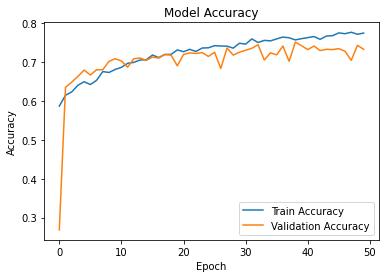

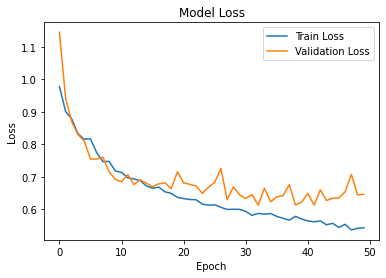

In [35]:
import matplotlib.pyplot as plt

# Plot Accuracy
# THE FIX: Changed 'acc' to 'accuracy' and 'val_acc' to 'val_accuracy'
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

# Plot Loss (This section was already correct!)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [37]:
pd.DataFrame(history.history)

,loss,accuracy,val_loss,val_accuracy
0,0.977496,0.586488,1.144727,0.268395
1,0.900708,0.614307,0.941560,0.634615
2,0.877111,0.622882,0.868344,0.647993
3,0.831746,0.640033,0.829303,0.663043
4,0.815513,0.649027,0.810394,0.678930
5,0.816456,0.641916,0.754475,0.666388
6,0.774338,0.652583,0.754375,0.679766
7,0.746614,0.675173,0.760168,0.679766
8,0.747274,0.672872,0.715965,0.701505
9,0.717717,0.680611,0.691496,0.708194


In [33]:
'''import tensorflow as tf
import numpy as np
import time

# 1. Write a pure Python generator function
def custom_signal_generator():

    # Imagine this is a list of 100 actual file paths
    fake_file_paths = [1,2,3,4,5,6,7,8,9]
    
    for path in fake_file_paths:
        # Simulate the time it takes to read a file from disk (e.g., 10ms)
        time.sleep(0.01) 
        
        # Simulate extracting a 9000-point ECG signal
        fake_ecg_signal = np.random.randn(9000, 1).astype(np.float32)
        
        # Simulate getting a categorical label (e.g., Class 0, 1, or 2)
        fake_label = np.random.randint(0, 3)
        
        # Yield them one at a time as raw Python/NumPy objects
        yield fake_ecg_signal, fake_label


# 2. Wrap the generator using TensorFlow's pipeline tool
dataset = tf.data.Dataset.from_generator(
    generator=custom_signal_generator,
    output_signature=(
        # TensorSpec defines what the model should expect for the input layer
        tf.TensorSpec(shape=(9000, 1), dtype=tf.float32), 
        # An empty shape () means a single scalar value (the integer label)
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
)

# 3. Add the industrial-grade optimizations
# Batch the single streams into blocks of 32
dataset = dataset.batch(32)

# Prefetch tells the CPU to prepare batch N+1 while the GPU trains on batch N
dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)


# 4. Test consume a single batch to verify shapes
for X_batch, y_batch in dataset.take(1):
    print("X_batch shape (Batch Size, Signal Length, Channels):", X_batch.shape)
    print("y_batch shape (Batch Size,):", y_batch.shape)
    print("y_batch contents:", y_batch.numpy())'''

'import tensorflow as tf\nimport numpy as np\nimport time\n\n# 1. Write a pure Python generator function\ndef custom_signal_generator():\n\n    # Imagine this is a list of 100 actual file paths\n    fake_file_paths = [1,2,3,4,5,6,7,8,9]\n    \n    for path in fake_file_paths:\n        # Simulate the time it takes to read a file from disk (e.g., 10ms)\n        time.sleep(0.01) \n        \n        # Simulate extracting a 9000-point ECG signal\n        fake_ecg_signal = np.random.randn(9000, 1).astype(np.float32)\n        \n        # Simulate getting a categorical label (e.g., Class 0, 1, or 2)\n        fake_label = np.random.randint(0, 3)\n        \n        # Yield them one at a time as raw Python/NumPy objects\n        yield fake_ecg_signal, fake_label\n\n\n# 2. Wrap the generator using TensorFlow\'s pipeline tool\ndataset = tf.data.Dataset.from_generator(\n    generator=custom_signal_generator,\n    output_signature=(\n        # TensorSpec defines what the model should expect for the i